# Data Cleaning & Visualization Project
## Exploring Retail Sales Data with Python

**Objective:** Clean a raw dataset, handle missing values, outliers, and duplicates, visualize important patterns, and communicate findings in plain language.

**Libraries:** `pandas`, `numpy`, `matplotlib`, and `seaborn`

This notebook creates a small, realistic sample dataset directly in Python, so it does not need an internet connection or an external CSV file. Some imperfections are intentionally included to practice data cleaning.

## 1. Import the libraries

If any library is missing in your environment, uncomment and run the installation line below.

In [1]:
# If needed, uncomment this line:
# %pip install pandas numpy matplotlib seaborn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", palette="deep")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Create a sample raw dataset

The dataset represents retail orders. It deliberately contains:
- Missing customer ages and product categories
- Duplicate order rows
- Invalid values (such as a negative quantity and an impossible age)
- A few unusually high order values that we will investigate as potential outliers

In [2]:
rng = np.random.default_rng(42)
n = 120

products = np.array(["Electronics", "Clothing", "Home", "Books", "Beauty"], dtype=object)
cities = np.array(["Hyderabad", "Bengaluru", "Mumbai", "Chennai", "Delhi"], dtype=object)

raw = pd.DataFrame({
    "Order_ID": [f"ORD{i:04d}" for i in range(1, n + 1)],
    "Order_Date": pd.to_datetime("2026-01-01") + pd.to_timedelta(rng.integers(0, 180, n), unit="D"),
    "Customer_Age": rng.integers(18, 66, n).astype(float),
    "City": rng.choice(cities, n),
    "Category": rng.choice(products, n, p=[0.22, 0.27, 0.20, 0.16, 0.15]),
    "Quantity": rng.integers(1, 6, n),
    "Unit_Price": np.round(rng.uniform(100, 5000, n), 2),
    "Payment_Method": rng.choice(["UPI", "Card", "Cash", "Net Banking"], n)
})

raw["Sales"] = (raw["Quantity"] * raw["Unit_Price"]).round(2)

# Introduce intentional data quality problems
raw.loc[[3, 17, 28, 49, 71, 95], "Customer_Age"] = np.nan
raw.loc[[8, 34, 87], "Category"] = np.nan
raw.loc[[12, 63], "City"] = np.nan
raw.loc[21, "Customer_Age"] = 250
raw.loc[45, "Quantity"] = -2
raw.loc[45, "Sales"] = raw.loc[45, "Quantity"] * raw.loc[45, "Unit_Price"]
raw.loc[110, "Unit_Price"] = 75000
raw.loc[110, "Sales"] = raw.loc[110, "Quantity"] * raw.loc[110, "Unit_Price"]

# Add duplicate rows intentionally
raw = pd.concat([raw, raw.iloc[[5, 22, 45]]], ignore_index=True)

print(f"Raw dataset shape: {raw.shape[0]} rows × {raw.shape[1]} columns")
display(raw.head(10))

Raw dataset shape: 123 rows × 9 columns


,Order_ID,Order_Date,Customer_Age,City,Category,Quantity,Unit_Price,Payment_Method,Sales
0,ORD0001,2026-01-17,39.0,Hyderabad,Beauty,4,4663.06,UPI,18652.24
1,ORD0002,2026-05-20,50.0,Mumbai,Beauty,4,686.69,Card,2746.76
2,ORD0003,2026-04-28,49.0,Hyderabad,Home,4,673.81,Net Banking,2695.24
3,ORD0004,2026-03-20,NaN,Chennai,Clothing,1,529.77,UPI,529.77
4,ORD0005,2026-03-19,59.0,Chennai,Books,5,3323.53,Net Banking,16617.65
5,ORD0006,2026-06-04,45.0,Hyderabad,Home,3,2151.18,Cash,6453.54
6,ORD0007,2026-01-16,21.0,Chennai,Clothing,2,3894.17,Cash,7788.34
7,ORD0008,2026-05-06,54.0,Mumbai,Electronics,3,3389.03,Card,10167.09
8,ORD0009,2026-02-06,45.0,Chennai,NaN,5,1734.83,Net Banking,8674.15
9,ORD0010,2026-01-17,48.0,Hyderabad,Clothing,5,4502.00,UPI,22510.00


## 3. Understand the raw data

First inspect the structure, data types, summary statistics, missing values, and duplicate rows. Always understand the data before changing it.

In [3]:
print("Dataset information:")
raw.info()

print("\nSummary statistics:")
display(raw.describe(include="all").T)

print("\nMissing values by column:")
missing_summary = raw.isna().sum().sort_values(ascending=False)
display(missing_summary[missing_summary > 0].to_frame("Missing_Count"))

print(f"\nExact duplicate rows: {raw.duplicated().sum()}")

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123 entries, 0 to 122
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order_ID        123 non-null    object        
 1   Order_Date      123 non-null    datetime64[ns]
 2   Customer_Age    117 non-null    float64       
 3   City            121 non-null    object        
 4   Category        120 non-null    object        
 5   Quantity        123 non-null    int64         
 6   Unit_Price      123 non-null    float64       
 7   Payment_Method  123 non-null    object        
 8   Sales           123 non-null    float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(4)
memory usage: 8.8+ KB

Summary statistics:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Order_ID,123,120,ORD0006,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_Date,123,NaN,NaN,NaN,2026-04-04 17:45:21.951219456,2026-01-02 00:00:00,2026-02-20 00:00:00,2026-04-05 00:00:00,2026-05-20 12:00:00,2026-06-25 00:00:00,NaN
Customer_Age,117.0,NaN,NaN,NaN,43.820513,18.0,32.0,41.0,52.0,250.0,23.064608
City,121,5,Hyderabad,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,120,5,Electronics,33,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,123.0,NaN,NaN,NaN,3.02439,-2.0,2.0,3.0,4.0,5.0,1.473612
Unit_Price,123.0,NaN,NaN,NaN,3189.670163,126.61,1079.965,2904.82,3923.48,75000.0,6698.193963
Payment_Method,123,4,Cash,39,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sales,123.0,NaN,NaN,NaN,10119.900894,-8816.16,3061.38,6453.54,11295.48,300000.0,27167.872576



Missing values by column:


,Missing_Count
Customer_Age,6
Category,3
City,2



Exact duplicate rows: 3


## 4. Visualize data quality before cleaning

The missing-value chart makes gaps easy to compare. The boxplots help identify suspicious numeric values, but an outlier is not automatically an error.

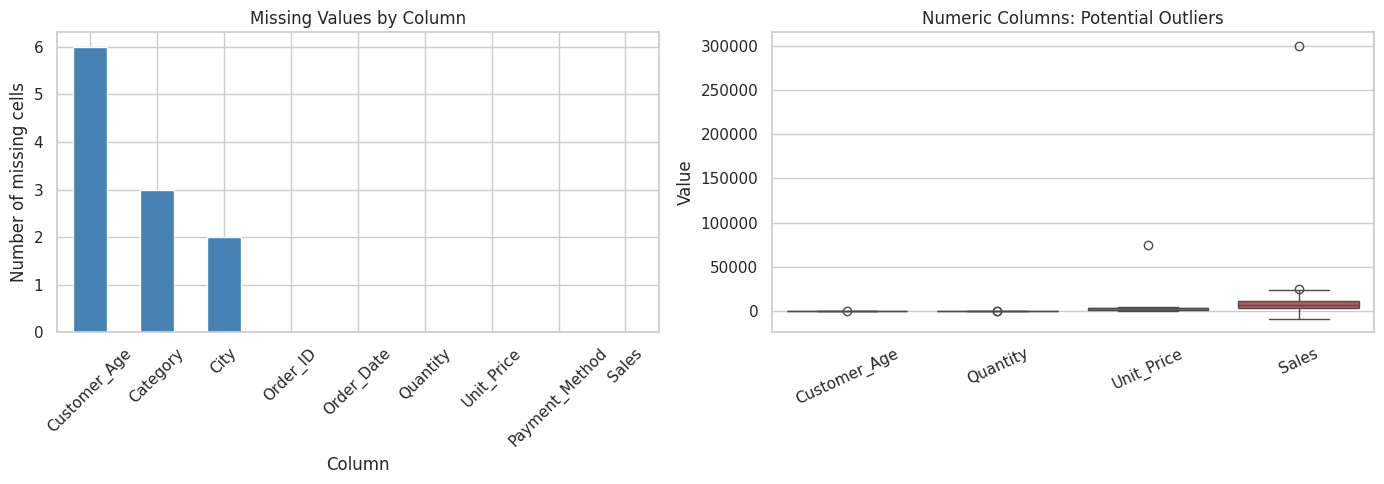

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

raw.isna().sum().sort_values(ascending=False).plot(
    kind="bar", ax=axes[0], color="steelblue"
)
axes[0].set_title("Missing Values by Column")
axes[0].set_xlabel("Column")
axes[0].set_ylabel("Number of missing cells")
axes[0].tick_params(axis="x", rotation=45)

sns.boxplot(data=raw[["Customer_Age", "Quantity", "Unit_Price", "Sales"]], ax=axes[1])
axes[1].set_title("Numeric Columns: Potential Outliers")
axes[1].set_ylabel("Value")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

## 5. Clean the dataset

Cleaning decisions used here:
1. Remove exact duplicate rows.
2. Convert impossible ages and non-positive quantities to missing values.
3. Fill missing ages with the median age.
4. Fill missing categories and cities with their most frequent values.
5. Recalculate sales from quantity × unit price to keep the measure consistent.

**Important:** We will not delete high sales values automatically. They may represent genuine high-value orders, so we will flag and inspect them first.

In [5]:
clean = raw.copy()

# 1. Remove exact duplicate records
rows_before = len(clean)
clean = clean.drop_duplicates().copy()
print(f"Removed {rows_before - len(clean)} duplicate rows.")

# 2. Standardize invalid values
clean.loc[~clean["Customer_Age"].between(18, 100), "Customer_Age"] = np.nan
clean.loc[clean["Quantity"] <= 0, "Quantity"] = np.nan
clean.loc[clean["Unit_Price"] <= 0, "Unit_Price"] = np.nan

# 3. Fill missing values
clean["Customer_Age"] = clean["Customer_Age"].fillna(clean["Customer_Age"].median())
for col in ["Category", "City", "Payment_Method"]:
    clean[col] = clean[col].fillna(clean[col].mode()[0])

# 4. For the one invalid quantity, use the median quantity (rounded to a whole unit)
clean["Quantity"] = clean["Quantity"].fillna(round(clean["Quantity"].median())).astype(int)

# 5. Recalculate the target measure
clean["Sales"] = (clean["Quantity"] * clean["Unit_Price"]).round(2)

# Ensure correct types
clean["Order_Date"] = pd.to_datetime(clean["Order_Date"])
clean["Customer_Age"] = clean["Customer_Age"].round().astype(int)

print(f"Clean dataset shape: {clean.shape[0]} rows × {clean.shape[1]} columns")
display(clean.head())
print("\nMissing values remaining:", int(clean.isna().sum().sum()))
print("Duplicate rows remaining:", int(clean.duplicated().sum()))

Removed 3 duplicate rows.
Clean dataset shape: 120 rows × 9 columns


,Order_ID,Order_Date,Customer_Age,City,Category,Quantity,Unit_Price,Payment_Method,Sales
0,ORD0001,2026-01-17,39,Hyderabad,Beauty,4,4663.06,UPI,18652.24
1,ORD0002,2026-05-20,50,Mumbai,Beauty,4,686.69,Card,2746.76
2,ORD0003,2026-04-28,49,Hyderabad,Home,4,673.81,Net Banking,2695.24
3,ORD0004,2026-03-20,41,Chennai,Clothing,1,529.77,UPI,529.77
4,ORD0005,2026-03-19,59,Chennai,Books,5,3323.53,Net Banking,16617.65



Missing values remaining: 0
Duplicate rows remaining: 0


## 6. Detect and handle outliers using the IQR method

The interquartile range (IQR) is Q3 − Q1. A value below Q1 − 1.5×IQR or above Q3 + 1.5×IQR is commonly flagged as a potential outlier.

For this exercise, we will **flag** unusual sales rather than remove them. This preserves potentially valid high-value orders and makes the analysis more transparent.

In [6]:
q1 = clean["Sales"].quantile(0.25)
q3 = clean["Sales"].quantile(0.75)
iqr = q3 - q1
lower_bound = max(0, q1 - 1.5 * iqr)
upper_bound = q3 + 1.5 * iqr

clean["Sales_Outlier"] = (clean["Sales"] < lower_bound) | (clean["Sales"] > upper_bound)

print(f"Q1: ₹{q1:,.2f}")
print(f"Q3: ₹{q3:,.2f}")
print(f"IQR: ₹{iqr:,.2f}")
print(f"Lower bound: ₹{lower_bound:,.2f}")
print(f"Upper bound: ₹{upper_bound:,.2f}")
print(f"Potential sales outliers: {int(clean['Sales_Outlier'].sum())}")

display(clean.loc[clean["Sales_Outlier"], ["Order_ID", "Category", "Quantity", "Unit_Price", "Sales"]].sort_values("Sales", ascending=False))

Q1: ₹3,104.11
Q3: ₹12,510.32
IQR: ₹9,406.22
Lower bound: ₹0.00
Upper bound: ₹26,619.65
Potential sales outliers: 1


,Order_ID,Category,Quantity,Unit_Price,Sales
110,ORD0111,Books,4,75000.0,300000.0


### Compare sales before and after optional outlier filtering

Filtering can be useful for a specific analysis, but it should not be done blindly. The chart below compares the distribution with all orders against the distribution excluding flagged sales outliers.

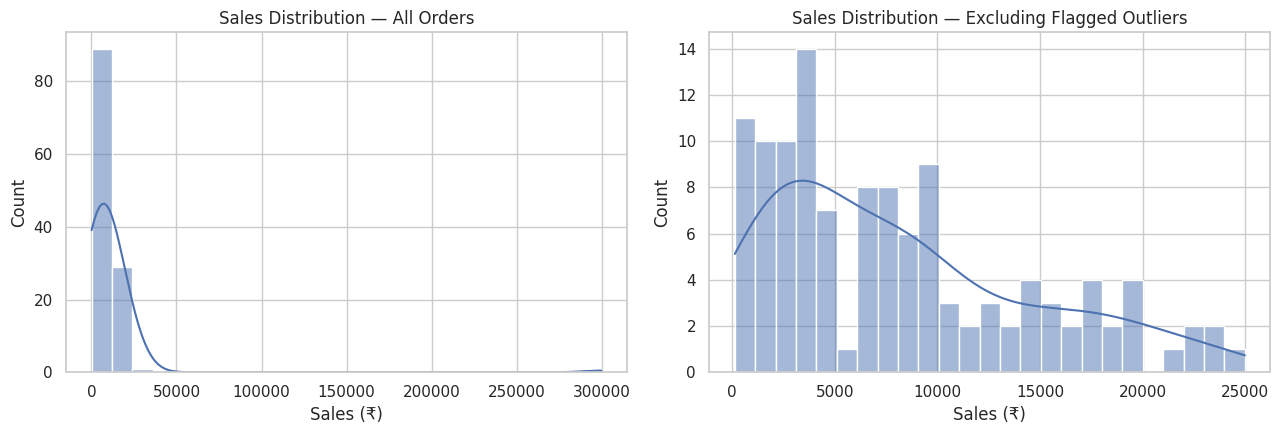

Use the filtered view only when justified by the question; keep the original cleaned data for transparent reporting.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(clean["Sales"], bins=25, kde=True, ax=axes[0])
axes[0].set_title("Sales Distribution — All Orders")
axes[0].set_xlabel("Sales (₹)")

sns.histplot(clean.loc[~clean["Sales_Outlier"], "Sales"], bins=25, kde=True, ax=axes[1])
axes[1].set_title("Sales Distribution — Excluding Flagged Outliers")
axes[1].set_xlabel("Sales (₹)")

plt.tight_layout()
plt.show()

print("Use the filtered view only when justified by the question; keep the original cleaned data for transparent reporting.")

## 7. Explore sales patterns with visualizations

We will answer a few practical questions:
- Which product categories generate the most revenue?
- How do sales vary over time?
- Which cities have higher total sales?
- Which payment methods are most frequently used?

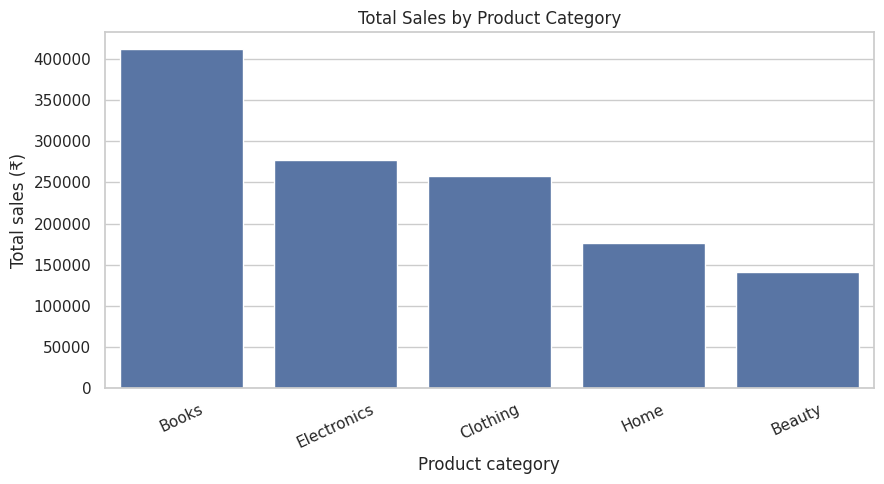

,Category,Sales
1,Books,411698.12
3,Electronics,277130.46
2,Clothing,258273.40
4,Home,176712.98
0,Beauty,141412.39


In [8]:
# A. Total sales by product category
category_sales = clean.groupby("Category", as_index=False)["Sales"].sum().sort_values("Sales", ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(data=category_sales, x="Category", y="Sales")
plt.title("Total Sales by Product Category")
plt.xlabel("Product category")
plt.ylabel("Total sales (₹)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

display(category_sales)

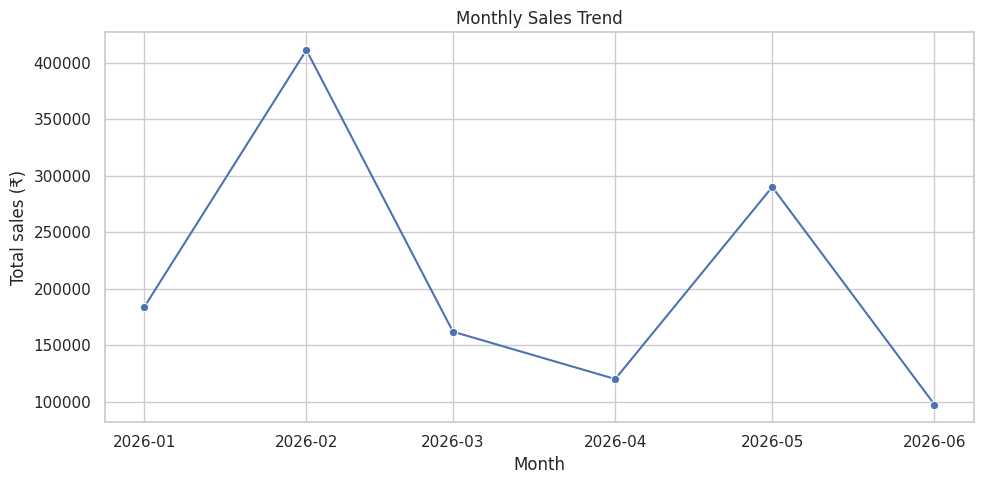

,Month,Sales
0,2026-01-01,183754.32
1,2026-02-01,411297.77
2,2026-03-01,162122.57
3,2026-04-01,120226.09
4,2026-05-01,290150.46
5,2026-06-01,97676.14


In [9]:
# B. Monthly sales trend
monthly_sales = (
    clean.assign(Month=clean["Order_Date"].dt.to_period("M").dt.to_timestamp())
    .groupby("Month", as_index=False)["Sales"].sum()
)

plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly_sales, x="Month", y="Sales", marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total sales (₹)")
plt.tight_layout()
plt.show()

display(monthly_sales)

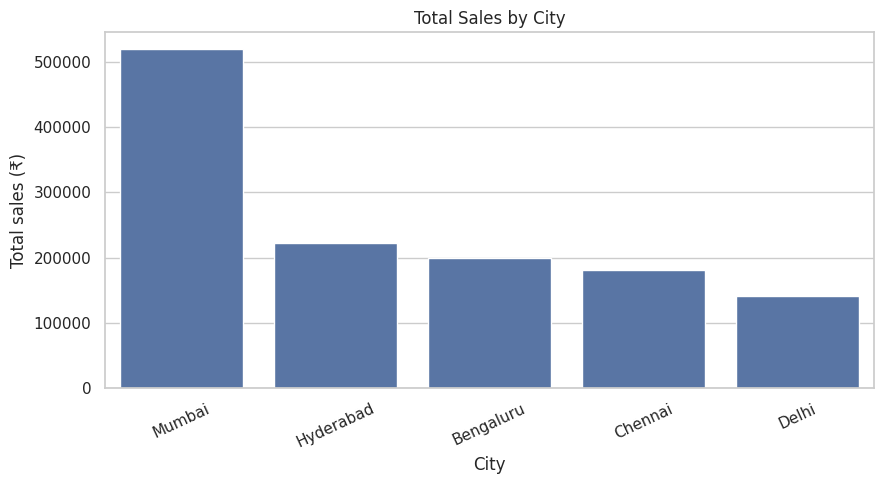

,City,Sales
4,Mumbai,519695.58
3,Hyderabad,222358.80
0,Bengaluru,199888.24
1,Chennai,181744.95
2,Delhi,141539.78


In [10]:
# C. Total sales by city
city_sales = clean.groupby("City", as_index=False)["Sales"].sum().sort_values("Sales", ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(data=city_sales, x="City", y="Sales")
plt.title("Total Sales by City")
plt.xlabel("City")
plt.ylabel("Total sales (₹)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

display(city_sales)

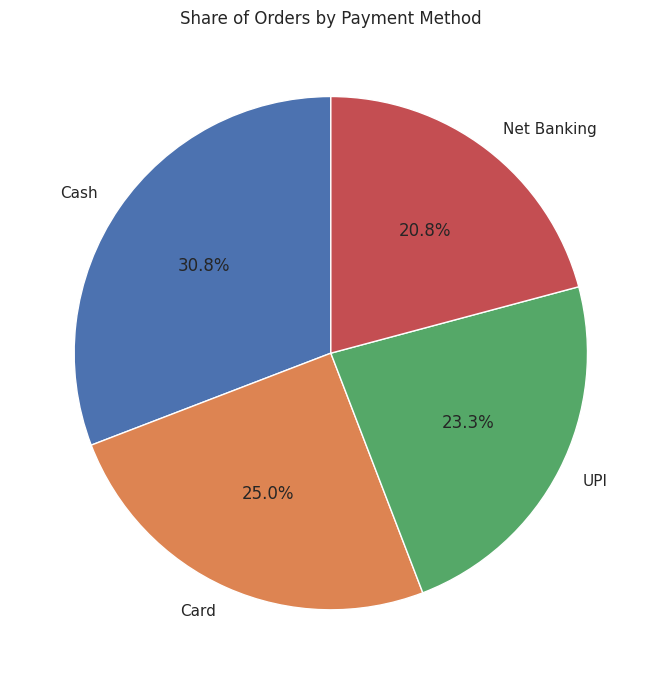

,Payment_Method,Orders
0,Cash,37
1,Card,30
2,UPI,28
3,Net Banking,25


In [11]:
# D. Payment method usage
payment_counts = clean["Payment_Method"].value_counts().rename_axis("Payment_Method").reset_index(name="Orders")

plt.figure(figsize=(7, 7))
plt.pie(payment_counts["Orders"], labels=payment_counts["Payment_Method"], autopct="%1.1f%%", startangle=90)
plt.title("Share of Orders by Payment Method")
plt.tight_layout()
plt.show()

display(payment_counts)

## 8. Create a compact KPI summary

A few summary metrics make the report easier to understand at a glance.

In [12]:
total_orders = clean["Order_ID"].nunique()
total_revenue = clean["Sales"].sum()
average_order_value = clean["Sales"].mean()
median_order_value = clean["Sales"].median()
outlier_count = int(clean["Sales_Outlier"].sum())

kpis = pd.DataFrame({
    "Metric": ["Unique orders", "Total revenue", "Average order value", "Median order value", "Flagged sales outliers"],
    "Value": [
        f"{total_orders:,}",
        f"₹{total_revenue:,.2f}",
        f"₹{average_order_value:,.2f}",
        f"₹{median_order_value:,.2f}",
        f"{outlier_count:,}"
    ]
})
display(kpis)

,Metric,Value
0,Unique orders,120
1,Total revenue,"₹1,265,227.35"
2,Average order value,"₹10,543.56"
3,Median order value,"₹6,982.30"
4,Flagged sales outliers,1


## 9. Tell the story: automatically summarize the results

The statements below are generated from this notebook's sample data. In a real project, validate these patterns with business context before making decisions.

In [13]:
top_category = category_sales.iloc[0]
top_city = city_sales.iloc[0]
top_payment = payment_counts.iloc[0]
best_month = monthly_sales.loc[monthly_sales["Sales"].idxmax()]

print("DATA STORY")
print("-" * 60)
print(f"1. Revenue: The dataset contains {total_orders} unique orders and total recorded sales of ₹{total_revenue:,.2f}.")
print(f"2. Product mix: {top_category['Category']} is the highest-revenue category, with ₹{top_category['Sales']:,.2f} in sales.")
print(f"3. Geography: {top_city['City']} records the highest total sales, at ₹{top_city['Sales']:,.2f}.")
print(f"4. Payments: {top_payment['Payment_Method']} is the most frequently used payment method ({int(top_payment['Orders'])} orders).")
print(f"5. Time: The strongest month in this sample is {best_month['Month'].strftime('%B %Y')}, with ₹{best_month['Sales']:,.2f} in sales.")
print(f"6. Data quality: {outlier_count} order(s) were flagged as potential sales outliers and should be reviewed, not automatically deleted.")
print("\nPossible next steps: compare categories by profit (if costs are available), investigate high-value orders, and analyze repeat customers.")

DATA STORY
------------------------------------------------------------
1. Revenue: The dataset contains 120 unique orders and total recorded sales of ₹1,265,227.35.
2. Product mix: Books is the highest-revenue category, with ₹411,698.12 in sales.
3. Geography: Mumbai records the highest total sales, at ₹519,695.58.
4. Payments: Cash is the most frequently used payment method (37 orders).
5. Time: The strongest month in this sample is February 2026, with ₹411,297.77 in sales.
6. Data quality: 1 order(s) were flagged as potential sales outliers and should be reviewed, not automatically deleted.

Possible next steps: compare categories by profit (if costs are available), investigate high-value orders, and analyze repeat customers.


## 10. Export the cleaned dataset

This optional cell saves the cleaned dataset as a CSV file in the notebook's current working directory. In Google Colab, the file will appear in the Files panel.

In [14]:
# Optional: save the cleaned data
clean.to_csv("cleaned_retail_sales.csv", index=False)
print("Saved: cleaned_retail_sales.csv")

Saved: cleaned_retail_sales.csv


## 11. Final checklist

- [x] Inspected the dataset and data types
- [x] Identified missing values
- [x] Removed duplicate rows
- [x] Corrected invalid ages and quantities
- [x] Filled missing values
- [x] Flagged potential outliers using the IQR rule
- [x] Created category, time, city, and payment visualizations
- [x] Produced a data-storytelling summary
- [x] Added an optional CSV export

### Conclusion

Data cleaning improves the reliability of analysis, while visualizations make patterns easier to communicate. The key lesson is to document every cleaning decision and investigate unusual values before removing them.